# 06 · Spatial analysis

Spacing metrics, their relationship to outcomes, and the court-control model.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C
pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110})
E = C.PROCESSED_DIR / "events"; D = C.DERIVED_DIR
rd  = lambda n: pd.read_parquet(D / f"{n}.parquet")
rev = lambda n: pd.read_parquet(E / f"{n}.parquet")
print("project:", C.PROJECT_ROOT.name)

project: basketball-intelligence


In [2]:
sp = rd("chance_spacing"); ch = rev("chances").rename(columns={"id":"chance_id"})
m = sp.merge(ch[["chance_id","pts_scored","outcome","transition"]], on="chance_id").dropna(subset=["pts_scored"])
print(f"{len(m):,} chances with spacing samples")
m[["hull_area_mean","mean_nn_dist_mean","width_mean","depth_mean","spacing_entropy_mean",
   "n_in_corners_mean","n_in_paint_mean","n_def_in_paint_mean"]].describe().round(2)

1,910 chances with spacing samples


,hull_area_mean,mean_nn_dist_mean,width_mean,depth_mean,spacing_entropy_mean,n_in_corners_mean,n_in_paint_mean,n_def_in_paint_mean
count,1895.00,1895.00,1895.00,1895.00,1895.00,1895.00,1895.00,1895.00
mean,579.43,14.94,36.94,29.08,0.57,0.49,0.71,1.37
std,165.53,2.38,6.65,6.83,0.08,0.44,0.55,0.77
min,94.13,5.52,8.50,12.09,0.16,0.00,0.00,0.00
25%,470.46,13.57,33.49,25.20,0.54,0.04,0.35,0.89
50%,579.38,15.02,38.55,27.92,0.59,0.44,0.62,1.25
75%,675.47,16.45,41.85,31.45,0.62,0.80,0.94,1.71
max,1389.77,26.08,47.28,73.39,0.77,2.00,4.00,5.00


                  n     hull    ppc     to
hull_area_mean                            
Q1 tightest     379  355.514  0.813  0.098
Q2              379  494.332  0.858  0.098
Q3              379  580.061  0.805  0.140
Q4              379  655.556  0.923  0.116
Q5 widest       379  811.679  0.929  0.145

Pearson r(hull, points) = nan  p = nan  -> no reliable relationship


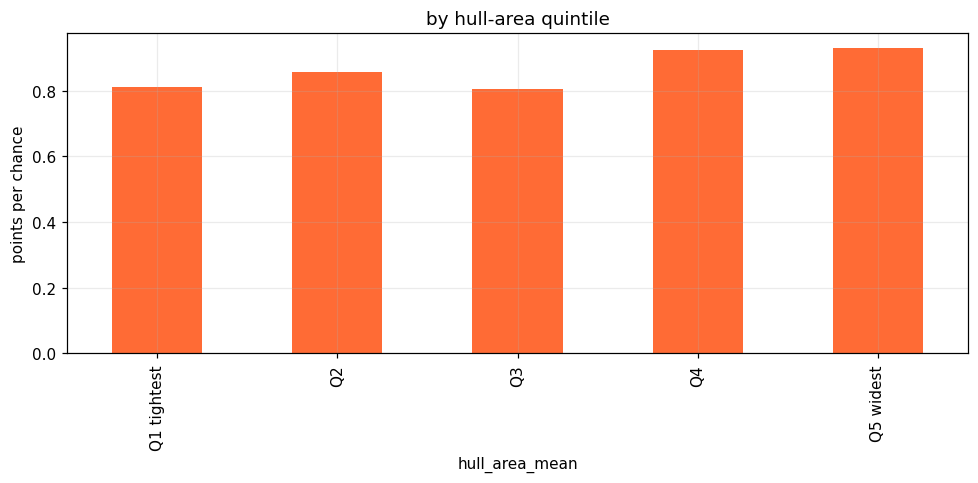

In [3]:
from scipy import stats
q = pd.qcut(m.hull_area_mean, 5, labels=["Q1 tightest","Q2","Q3","Q4","Q5 widest"])
g = m.groupby(q, observed=True).agg(n=("chance_id","size"), hull=("hull_area_mean","mean"),
    ppc=("pts_scored","mean"), to=("outcome", lambda s: s.eq("TO").mean()))
print(g.round(3))
r, p = stats.pearsonr(m.hull_area_mean, m.pts_scored)
print(f"\nPearson r(hull, points) = {r:.4f}  p = {p:.3f}  -> no reliable relationship")
g.ppc.plot.bar(color="#FF6B35"); plt.ylabel("points per chance"); plt.title("by hull-area quintile")
plt.tight_layout(); plt.show()

## Spacing does move the inputs to a good shot

In [4]:
sh = rd("shots_features").merge(sp[["chance_id","hull_area_mean"]], on="chance_id").dropna(subset=["hull_area_mean"])
q2 = pd.qcut(sh.hull_area_mean, 5, labels=["Q1","Q2","Q3","Q4","Q5"])
sh.groupby(q2, observed=True).agg(n=("id","size"), fg=("outcome","mean"), xfg=("xfg","mean"),
  sq=("shot_quality","mean"), def_dist=("closest_def_dist","mean"),
  open_rate=("contested", lambda s: 1-s.mean())).round(3)

,n,fg,xfg,sq,def_dist,open_rate
hull_area_mean,,,,,,
Q1,279,0.376,0.450,43.095,4.283,0.264
Q2,279,0.387,0.438,42.153,3.968,0.234
Q3,279,0.405,0.455,42.693,4.140,0.275
Q4,279,0.437,0.466,43.817,4.332,0.291
Q5,279,0.480,0.482,45.692,4.616,0.283


## Court control at one instant

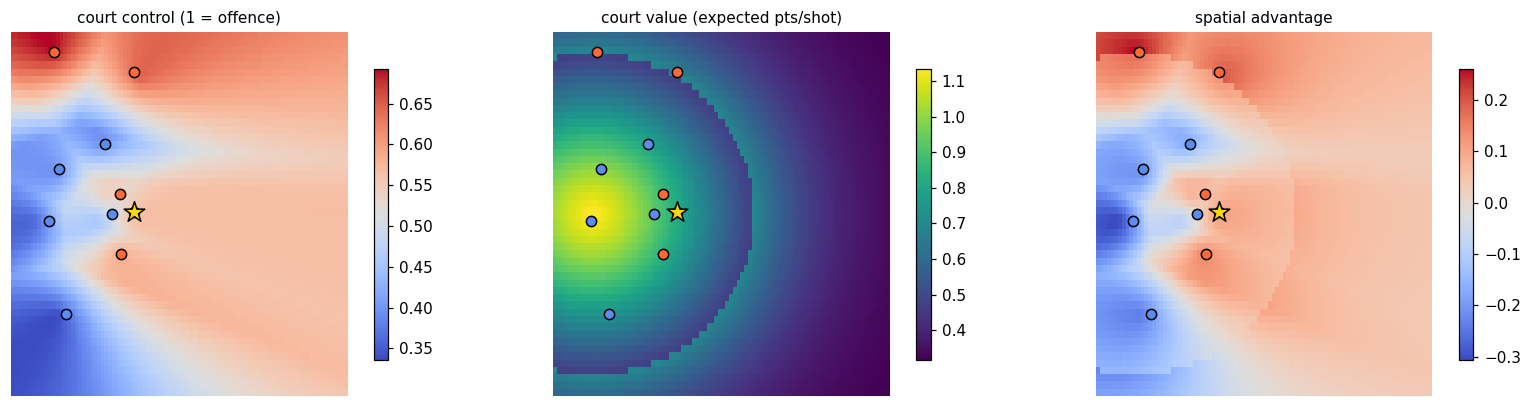

offence controls 73% of the half court at this instant


In [5]:
from src.spatial import geometry as G
from src.preprocessing import court
gid = int(sh.game_id.iloc[0])
row = sh[(sh.game_id == gid) & sh.location_x.notna()].iloc[10]
t = pd.read_parquet(C.PROCESSED_DIR / f"tracking_enriched/{gid}.parquet",
                    columns=["frame_idx","team_id","x_att","y_att","vx_att","vy_att"],
                    filters=[("frame_idx","=",int(row.start_frame))])
off = t[t.team_id == row.off_team_id]; dfn = t[t.team_id != row.off_team_id]
oxy = off[["x_att","y_att"]].to_numpy(float); dxy = dfn[["x_att","y_att"]].to_numpy(float)
ov = np.nan_to_num(off[["vx_att","vy_att"]].to_numpy(float)); dv = np.nan_to_num(dfn[["vx_att","vy_att"]].to_numpy(float))
gx, gy = G.make_grid(90, 50)
ctrl = G.court_control(oxy, ov, dxy, dv, gx, gy)
val  = G.court_value_surface(gx, gy)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, z, ttl, cm in [(ax[0], ctrl, "court control (1 = offence)", "coolwarm"),
                      (ax[1], val, "court value (expected pts/shot)", "viridis"),
                      (ax[2], (ctrl-.5)*2*val, "spatial advantage", "coolwarm")]:
    im = a.pcolormesh(gx, gy, z, cmap=cm, shading="auto")
    a.scatter(*oxy.T, c="#FF6B35", s=45, ec="k", zorder=3)
    a.scatter(*dxy.T, c="#5B8DEF", s=45, ec="k", zorder=3)
    a.scatter([row.location_x],[row.location_y], marker="*", s=200, c="gold", ec="k", zorder=4)
    a.set_title(ttl, fontsize=10); a.set_aspect("equal"); a.axis("off"); plt.colorbar(im, ax=a, shrink=.8)
plt.tight_layout(); plt.show()
print(f"offence controls {(ctrl>.5).mean():.0%} of the half court at this instant")